In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.cosmology import FlatLambdaCDM
from lenstronomy.SimulationAPI.sim_api import SimAPI
from lenstronomy.Util import param_util
from lenstronomy.LensModel.lens_model import LensModel
from lenstronomy.LensModel.lens_model_extensions import LensModelExtensions

In [2]:
NUMPIX = 100                       # 100 px x 0.1" = 10" field
BAND = {
    'pixel_scale': 0.1,            # paper
    'seeing': 0.16,                # paper (PSF FWHM, Gaussian approximation)
    'exposure_time': 565,          # memory, per exposure
    'num_exposures': 4,            # memory
    'magnitude_zero_point': 25.6,  # memory -> use MAGZERO from the Q1 header
    'read_noise': 4.5,             # memory
    'ccd_gain': 3.1,               # memory (unused while counts are in e-)
    'sky_brightness': 22.4,        # memory
    'psf_type': 'GAUSSIAN',
}
KWARGS_NUMERICS = {'supersampling_factor': 3}

COSMO = FlatLambdaCDM(H0=70, Om0=0.3)
C_KMS = 299792.458
ARCSEC_PER_RAD = 206264.806

In [4]:
_REF_SIM = SimAPI(NUMPIX, BAND, {'lens_model_list': ['SIE'], 'lens_light_model_list': [],
                                 'source_light_model_list': []})
SIGMA_BKG = _REF_SIM.noise_for_model(model=np.zeros((NUMPIX, NUMPIX)), background_noise=True,
                                     poisson_noise=False).std()



/Users/shubhisharvil/lens_env/lib/python3.10/site-packages/numpy/lib/histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


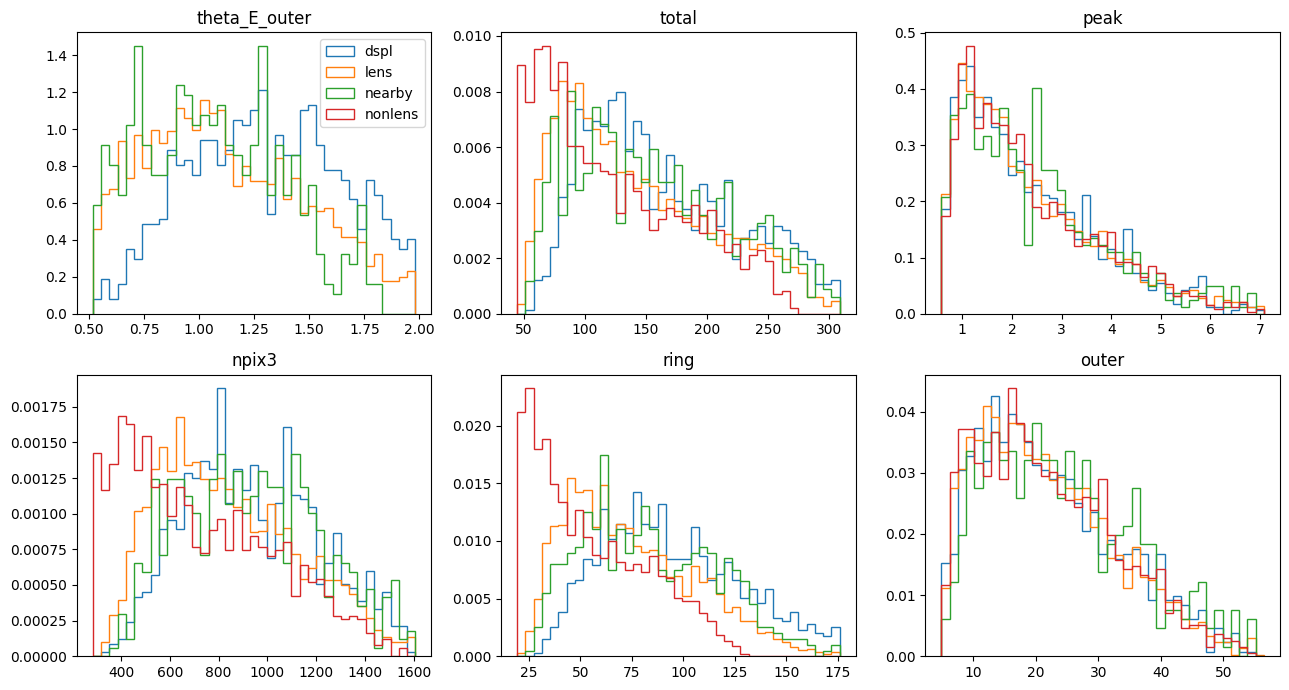

vs             lens  nearby  nonlens
feature                             
npix3          0.17    0.06     0.35
outer          0.03    0.08     0.03
peak           0.02    0.06     0.02
ring           0.26    0.14     0.48
theta_E_outer  0.23    0.27      NaN
total          0.18    0.09     0.32
AUROC from Einstein radius alone: 0.654
AUROC from summary stats alone: 0.814


In [5]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_auc_score

OUT = "/Users/shubhisharvil/ACM_Ruby/data"
df = pd.read_csv("/Users/shubhisharvil/ACM_Ruby/data/dataset.csv")
df = df[df.class_name != "doublecusp"].copy()
df["theta_E_outer"] = df["theta_E"].fillna(df["theta_E2"])   # dspl -> outer ring
df["is_compound"] = df["is_dspl"]

# ---- per-image summary stats (things a model could see) ----
yy, xx = np.indices((NUMPIX, NUMPIX))
r = np.hypot(xx - (NUMPIX - 1) / 2, yy - (NUMPIX - 1) / 2) * BAND["pixel_scale"]

def img_stats(id_str):
    im = np.load(f"{OUT}/raw/{id_str}.npy")
    return dict(total=im.sum(), peak=im.max(), std=im.std(),
                npix3=int((im > 3 * SIGMA_BKG).sum()),
                core=im[r < 0.5].sum(),
                ring=im[(r >= 0.5) & (r < 2.5)].sum(),
                outer=im[r >= 2.5].sum())

S = pd.DataFrame([img_stats(i) for i in df.id_str], index=df.index)
df = pd.concat([df, S], axis=1)

# ---- 1. histograms: compound vs each negative class ----
feats = ["theta_E_outer", "total", "peak", "npix3", "ring", "outer"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, f in zip(axes.ravel(), feats):
    lo, hi = np.nanpercentile(df[f], [0.5, 99.5])
    bins = np.linspace(lo, hi, 40)
    for cls, g in df.groupby("class_name"):
        ax.hist(g[f].dropna(), bins=bins, histtype="step", density=True, label=cls)
    ax.set_title(f)
axes[0, 0].legend()
plt.tight_layout(); plt.show()

# ---- 2. KS test: compound vs each negative class ----
pos = df[df.is_compound == 1]
rows = []
for cls in ["lens", "nearby", "nonlens"]:
    neg = df[df.class_name == cls]
    for f in feats:
        if neg[f].notna().sum() == 0:
            continue
        rows.append((cls, f, ks_2samp(pos[f].dropna(), neg[f].dropna()).statistic))
print(pd.DataFrame(rows, columns=["vs", "feature", "KS"]).pivot(index="feature", columns="vs", values="KS").round(2))

# ---- 3. radius-only shortcut: dspl vs lens+nearby ----
sub = df[df.class_name.isin(["dspl", "lens", "nearby"])]
print("AUROC from Einstein radius alone:", round(roc_auc_score(sub.is_compound, sub.theta_E_outer), 3))

# ---- 4. trivial classifier on image stats only ----
X = df[["total", "peak", "std", "npix3", "core", "ring", "outer"]].values
y = df.is_compound.values
p = cross_val_predict(GradientBoostingClassifier(), X, y,
                      cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]
print("AUROC from summary stats alone:", round(roc_auc_score(y, p), 3))

In [ ]:
cols = ["total", "peak", "std", "npix3", "core", "ring", "outer"]
def stats_auroc(d):
    p = cross_val_predict(GradientBoostingClassifier(), d[cols].values, d.is_compound.values,
                          cv=StratifiedKFold(5, shuffle=True, random_state=0),
                          method="predict_proba")[:, 1]
    return round(roc_auc_score(d.is_compound, p), 3)

# (a) compounds vs other lenses only (drop nonlens)
sub = df[df.class_name.isin(["dspl", "lens", "nearby"])]
print("stats-only, lenses only:", stats_auroc(sub))

# (b) the same, with negatives matched to the dspl outer-radius distribution
pos = sub[sub.is_compound == 1]
neg = sub[sub.is_compound == 0]
edges = np.quantile(pos.theta_E_outer, np.linspace(0, 1, 9))
keep = []
for lo, hi in zip(edges[:-1], edges[1:]):
    n_pos = ((pos.theta_E_outer >= lo) & (pos.theta_E_outer <= hi)).sum()
    cand = neg[(neg.theta_E_outer >= lo) & (neg.theta_E_outer <= hi)]
    keep.append(cand.sample(min(len(cand), 2 * n_pos), random_state=0))
matched = pd.concat([pos] + keep)
print("stats-only, radius-matched:", stats_auroc(matched))

stats-only, lenses only: 0.751
stats-only, radius-matched: 0.768
